# Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa  
        

Levando em conta a base de dados _Dry Bean Dataset_, esta parte do Projeto Prático diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo feedforward multilayer perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Busca em Grade

Uma maneira padrão de escolher os parâmetros de um modelo de Machine Learning é por meio de uma busca em grade via força bruta. O algoritmo da busca em grade é dado como segue:

1. Escolha a métrica de desempenho que você deseja maximizar (por exemplo, o F-Score com média macro, adequado a um problema multiclasse com classes desbalanceadas)  
2. Escolha o algoritmo de Machine Learning (exemplo: redes neurais artificiais). Em seguida, defina os parâmetros ou hiperparâmetros deste tipo de modelo sobre os quais você deseja otimizar (número de épocas, taxa de aprendizado, etc.) e construa um array de valores a serem testados para cada parâmetro ou hiperparâmetro.  
3. Defina a grade de busca, a qual é dada como o produto cartesiano dos valores de cada parâmetro a ser testado. Por exemplo, para os arrays [50, 100, 1000] e [10, 15], tem-se que a grade é [(50,10), (50,15), (100,10), (100,15), (1000,10), (1000,15)].
4. Para cada combinação de parâmetros a serem otimizados, utilize _apenas o conjunto de treinamento_ para realizar uma validação cruzada (holdout ou k-fold) e calcule a métrica de avaliação nos conjuntos de validação gerados por ela. O conjunto de teste não participa da busca. Vamos efetuar validação cruzada holdout 70/30 estratificada.
5. Escolha a combinação de parâmetros que maximiza a métrica de avaliação na validação. Este é o modelo otimizado, que deve então ser reavaliado uma única vez no conjunto de teste.

Por que esta abordagem funciona? Porque a busca em grade efetua uma pesquisa extensiva sobre as possíveis combinações de valores para cada um dos parâmetros a serem ajustados. Para cada combinação, ela estima a performance do modelo em dados não utilizados no seu treinamento (os conjuntos de validação). Por fim, o modelo com melhor métrica de desempenho é escolhido. Tem-se então que este modelo é o que tem maior chance de generalizar bem mediante dados nunca antes vistos, e o conjunto de teste, que não foi utilizado na busca, fornece a estimativa final e não enviesada desse desempenho.

## Efetuando a Busca em Grade sobre Hiperparâmetros das Top-6 RNAs

Considerando a etapa anterior do projeto prático, foram identificadas pelo menos 6 melhores Redes Neurais para o problema da classificação multiclasse das variedades de feijão no conjunto de dados selecionado. Estas redes podem ter sido obtidas pela estratégia própria ou pela regra da Pirâmide Geométrica, e todas utilizam os 16 atributos numéricos como preditores.

A primeira etapa desta segunda parte do projeto consiste em trazer para este notebook estas seis arquiteturas, ressaltando:

1. Número de neurônios ocultos por camada  
2. Função de Ativação  
3. Estratégia de origem da arquitetura (Própria ou Pirâmide Geométrica)  
4. Desempenho médio ± desvio padrão nos testes anteriores  
5. Número de repetições que a equipe conseguiu realizar para verificar os resultados  

Elabore uma busca em grade sobre estas arquiteturas que contemple variações nos hiperparâmetros a seguir, conforme documentação de [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

A. Solver (não usar o LBFGS, pois é mais adequado para datasets pequenos)  
B. Batch Size  
C. Learning Rate Init  
D. Paciência  
E. Épocas  

Nesta busca em grade, contemple a utilização do objeto [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), com a métrica escolhida no parâmetro `scoring` (por exemplo, `'f1_macro'`) e a validação cruzada realizada apenas com o conjunto de treinamento (já escalonado conforme a estratégia da etapa anterior).

In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])

0

In [ ]:
# Reservado para a importação de bibliotecas
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, ParameterGrid, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelBinarizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    recall_score,
    f1_score
)
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
import os
import joblib
from sklearn.pipeline import Pipeline

In [ ]:
RANDOM_STATE = 42

dry_bean = fetch_ucirepo(id=602)
features = dry_bean.data.features

x = features
y = dry_bean.data.targets

lb = LabelBinarizer() # one hot para as labels
y = lb.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y
)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
architectures = [
    # estratégia própria
    ((2, (20, 20), 'relu'), "adam", 200),
    ((2, (20, 20), 'relu'), "adam", 150),
    ((2, (10, 20), 'relu'), "adam", 200),
    # pirâmide geométrica
    ((2, (16, 16), 'relu'), "adam", 200),
    ((3, (5, 10, 17), 'relu'), "adam", 200),
    ((1, (32,), 'relu'), "adam", 200)
]

hidden_layer_sizes = list({arc[0][1] for arc in architectures})
activation = ["relu"]
max_iter = [150, 200]
solver = ["adam"]
batch_size = [128, 264]
learning_rate_init = [0.01, 0.1]
n_iter_no_change = [10, 20] # Paciência

parameters = dict(
    hidden_layer_sizes=hidden_layer_sizes,
    activation=activation,
    max_iter=max_iter,
    solver=solver,
    batch_size=batch_size,
    learning_rate_init=learning_rate_init,
    n_iter_no_change=n_iter_no_change
)

combinations = list(ParameterGrid(parameters))

In [ ]:
clf = GridSearchCV(
    MLPClassifier(
        random_state=RANDOM_STATE
    ),
    parameters,
    scoring="f1_macro",
    cv=5, # validação cruzada já usando 5 folds
)

best_estimator = clf.fit(
    X_train,
    y_train
)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

In [ ]:
best_estimator

GridSearchCV(cv=5, estimator=MLPClassifier(random_state=42),
             param_grid={'activation': ['relu'], 'batch_size': [128, 264],
                         'hidden_layer_sizes': [(16, 16), (5, 10, 17), (20, 20),
                                                (10, 20), (32,)],
                         'learning_rate_init': [0.01, 0.1],
                         'max_iter': [150, 200], 'n_iter_no_change': [10, 20],
                         'solver': ['adam']},
             scoring='f1_macro')

## Validação Cruzada k-fold

Na elaboração da busca em grade, vamos avaliar os modelos propostos segundo uma estratégia de validação cruzada ainda não explorada até o momento: a validação cruzada *k-fold*. Segundo a mesma, o conjunto de dados é particionado em *k* partes (*folds*): a cada iteração, separa-se uma das partes para validação e o modelo é treinado com as *k-1* partes remanescentes. Valores sugestivos de *k* na literatura são *k* = 3, 5 ou 10, pois o custo computacional desta validação dos modelos é alto. A métrica de desempenho é resultante da média dos desempenhos nas *k* iterações. A figura a seguir ilustra a ideia desta avaliação:

<img src="https://ethen8181.github.io/machine-learning/model_selection/img/kfolds.png" width="600">

Considerando a métrica de desempenho F1-Score (com média macro, dado que o problema possui 7 classes), considere a validação cruzada 5-fold estratificada para aferir os resultados da busca em grade anterior, realizada *apenas com o conjunto de treinamento*. O conjunto de teste deve ser utilizado uma única vez, para avaliar a melhor configuração encontrada.

In [ ]:
y_train_classes = y_train.argmax(axis=1)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(X_train, y_train_classes))

grid_search = GridSearchCV(
    MLPClassifier(random_state=RANDOM_STATE),
    param_grid=parameters,
    scoring="f1_macro",
    cv=folds,
    n_jobs=-1,
    refit=True,  # reajusta a melhor combinação com todo o conjunto de treinamento
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    grid_search.fit(X_train, y_train)

n_comb = len(grid_search.cv_results_["params"])
print(f"Combinações avaliadas: {n_comb} | treinamentos (combinações x folds): {n_comb * skf.get_n_splits()}")

resultados = pd.DataFrame(grid_search.cv_results_)
colunas = {
    "rank_test_score": "Ranking",
    "param_hidden_layer_sizes": "Neuronios por camada",
    "param_batch_size": "Batch size",
    "param_learning_rate_init": "Learning rate init",
    "param_n_iter_no_change": "Paciencia",
    "param_max_iter": "Épocas",
    "mean_test_score": "F1 macro (média)",
    "std_test_score": "F1 macro (desvio)",
}
top10 = resultados.sort_values("rank_test_score")[list(colunas)].head(10).rename(columns=colunas)
top10.reset_index(drop=True)

Combinações avaliadas: 80 | treinamentos (combinações x folds): 400


,Ranking,Neuronios por camada,Batch size,Learning rate init,Paciencia,Épocas,F1 macro (média),F1 macro (desvio)
0,1,"(32,)",264,0.01,10,150,0.940149,0.003440
1,1,"(32,)",264,0.01,10,200,0.940149,0.003440
2,3,"(32,)",264,0.01,20,200,0.939893,0.003976
3,4,"(32,)",128,0.01,10,200,0.939852,0.002284
4,4,"(32,)",128,0.01,10,150,0.939852,0.002284
5,6,"(32,)",128,0.01,20,150,0.939763,0.003312
6,7,"(16, 16)",128,0.01,10,200,0.939273,0.003110
7,7,"(16, 16)",128,0.01,10,150,0.939273,0.003110
8,9,"(20, 20)",264,0.01,10,200,0.938741,0.003125
9,10,"(20, 20)",264,0.01,20,200,0.938695,0.002501


## Identificando a mellhor solução

Como resultado da busca em grade com validação cruzada 5-fold, identifique o modelo otimizado com melhor desempenho para o problema. Apresente claramente este modelo, sua arquitetura (número de camadas ocultas, neurônios por camada e função de ativação), os hiperparâmetros otimizados (solver, batch size, taxa de aprendizado inicial, paciência e épocas) e os resultados (F1-Score macro) para cada um dos folds avaliados, junto com a média ± desvio padrão entre os folds. Em seguida, reavalie este modelo uma única vez no conjunto de teste, apresentando a matriz de confusão, a acurácia e o F1-Score macro. Esta é a melhor solução identificada em decorrência deste projeto.

In [ ]:
best_idx = grid_search.best_index_
best_params = grid_search.best_params_
cv_res = grid_search.cv_results_
n_folds = grid_search.n_splits_

hidden = best_params["hidden_layer_sizes"]

print("Arquitetura do modelo otimizado:")
print(f"Camadas ocultas:        {len(hidden)}")
print(f"Neurônios por camada:   {hidden}")
print(f"Função de ativação:     {best_params['activation']}")

print("\nHiperparâmetros otimizados:")
print(f"Solver:                       {best_params['solver']}")
print(f"Batch size:                   {best_params['batch_size']}")
print(f"Taxa de aprendizado inicial:  {best_params['learning_rate_init']}")
print(f"Paciência: {best_params['n_iter_no_change']}")
print(f"Épocas:            {best_params['max_iter']}")
print(f"Épocas executadas:   {grid_search.best_estimator_.n_iter_}")

fold_scores = np.array([cv_res[f"split{k}_test_score"][best_idx] for k in range(n_folds)])

print("\nF1-Score macro por fold (validação cruzada 5-fold estratificada)")
print(pd.DataFrame({"Fold": range(1, n_folds + 1), "F1-Score macro": fold_scores}).to_string(index=False))
print(f"\nF1-Score macro (média / desvio padrão): {fold_scores.mean():.4f} / {fold_scores.std():.4f}")

Arquitetura do modelo otimizado:
Camadas ocultas:        1
Neurônios por camada:   (32,)
Função de ativação:     relu

Hiperparâmetros otimizados:
Solver:                       adam
Batch size:                   264
Taxa de aprendizado inicial:  0.01
Paciência: 10
Épocas:            150
Épocas executadas:   98

F1-Score macro por fold (validação cruzada 5-fold estratificada)
 Fold  F1-Score macro
    1        0.942516
    2        0.939805
    3        0.937847
    4        0.935385
    5        0.945192

F1-Score macro (média / desvio padrão): 0.9401 / 0.0034


Acurácia no conjunto de teste:                      0.9322
F1-Score macro no conjunto de teste:       0.9432
F1-Score macro no teste:     0.9414


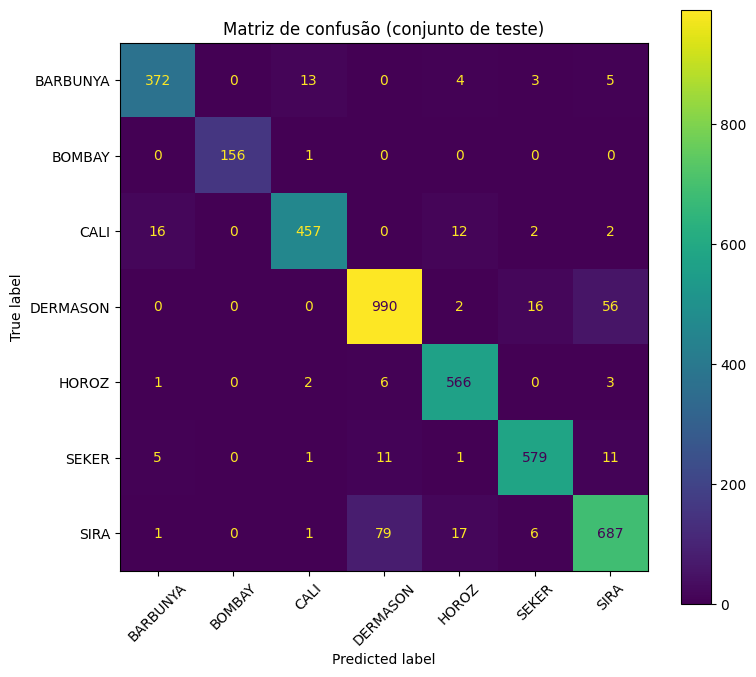

In [ ]:
best_model = grid_search.best_estimator_

y_test_classes = y_test.argmax(axis=1)
y_pred_classes = best_model.predict_proba(X_test).argmax(axis=1)

acc = accuracy_score(y_test_classes, y_pred_classes)
f1_macro = f1_score(y_test_classes, y_pred_classes, average="macro")
f1_macro_cv = f1_score(y_test, best_model.predict(X_test), average="macro")

print(f"Acurácia no conjunto de teste:                      {acc:.4f}")
print(f"F1-Score macro no conjunto de teste:       {f1_macro:.4f}")
print(f"F1-Score macro no teste:     {f1_macro_cv:.4f}")

cm = confusion_matrix(y_test_classes, y_pred_classes, labels=range(len(lb.classes_)))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=lb.classes_).plot(ax=ax, xticks_rotation=45)
ax.set_title("Matriz de confusão (conjunto de teste)")
plt.tight_layout()
plt.show()

## Empacotando a solução

Suponha que você deve entregar este classificador a uma cooperativa ou órgão responsável pelo controle de qualidade e classificação de grãos de feijão seco. Para tanto, você deve fazer uma preparação do mesmo para utilização neste cenário. Uma vez que já identificou os melhores hiperparâmetros, o passo remanescente consiste em treinar o modelo com estes valores e todos os dados disponíveis, salvando o modelo treinado (pesos da rede e o escalonador dos atributos) ao final para entrega ao cliente. Assim, finalize o projeto prático realizando tais passos.

1. Consulte a documentação a seguir:
https://scikit-learn.org/stable/modules/model_persistence.html  
2. Treine o modelo com todos os dados, utilizando a arquitetura e os hiperparâmetros otimizados. O escalonador (`StandardScaler`) deve ser ajustado com todos os dados e salvo junto com a rede, preferencialmente em um único `Pipeline`  
3. Salve o modelo em disco  
4. Construa uma rotina que recupere o modelo em disco  
5. Mostre que a rotina é funcional, fazendo previsões com todos os elementos do dataset e exibindo uma matriz de confusão das mesmas. Como o modelo foi treinado com todos os dados, esta matriz serve apenas para verificar o funcionamento da rotina e não como estimativa de desempenho, que é dada pelos resultados da validação cruzada e do conjunto de teste

Modelo salvo em 'modelo_feijao_seco.joblib' (35.1 KB)
Classes salvas em 'classes_feijao_seco.joblib'

Previsões do modelo carregado: True
Amostras previstas: 13611


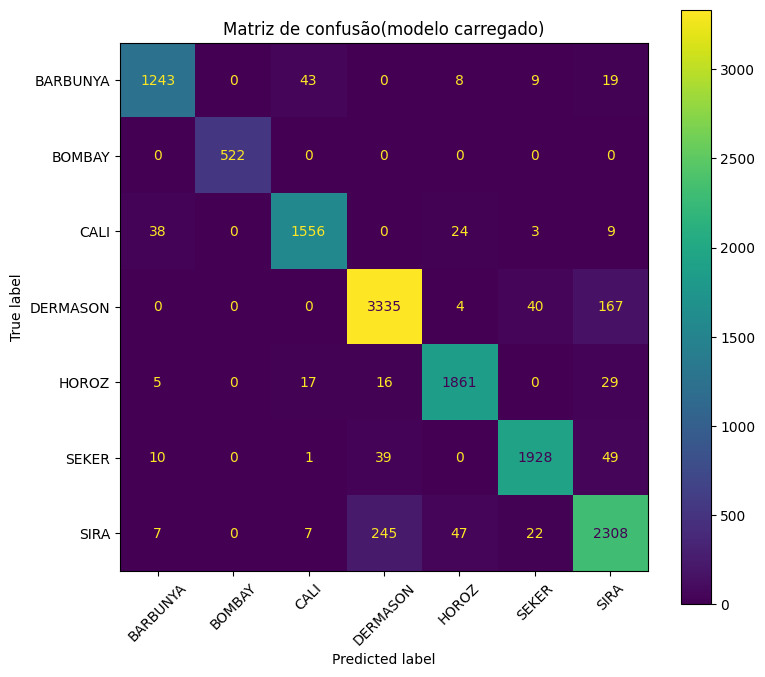

In [ ]:
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(**grid_search.best_params_, random_state=RANDOM_STATE)),
])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    final_model.fit(x, y)

#salvando o modelo em disco
MODEL_PATH = "modelo_feijao_seco.joblib"
CLASSES_PATH = "classes_feijao_seco.joblib"

joblib.dump(final_model, MODEL_PATH)
joblib.dump(list(lb.classes_), CLASSES_PATH)
print(f"Modelo salvo em '{MODEL_PATH}' ({os.path.getsize(MODEL_PATH) / 1024:.1f} KB)")
print(f"Classes salvas em '{CLASSES_PATH}'")


def carregar_modelo(caminho_modelo=MODEL_PATH, caminho_classes=CLASSES_PATH):
    """Carrega do disco o pipeline e os nomes das classes."""
    modelo = joblib.load(caminho_modelo)
    classes = joblib.load(caminho_classes)
    return modelo, classes


def prever_variedades(modelo, classes, atributos):
    """Recebe os 16 atributos e devolve a variedade de feijão prevista."""
    probabilidades = modelo.predict_proba(atributos)
    return np.array(classes)[probabilidades.argmax(axis=1)]


modelo_carregado, classes = carregar_modelo()
y_pred_nomes = prever_variedades(modelo_carregado, classes, x)
y_true_nomes = np.array(classes)[y.argmax(axis=1)]

pred_memoria = np.array(classes)[final_model.predict_proba(x).argmax(axis=1)]
print(f"\nPrevisões do modelo carregado: {np.array_equal(y_pred_nomes, pred_memoria)}")
print(f"Amostras previstas: {len(y_pred_nomes)}")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_true_nomes, y_pred_nomes, labels=classes, xticks_rotation=45, ax=ax
)
ax.set_title("Matriz de confusão(modelo carregado)")
plt.tight_layout()
plt.show()